# Semiconductor Supply Pressure → U.S. Communications Equipment Manufacturing

**Reproducible historical macro lead-indicator falsification (28 October 2026).**

**Publication gate:** A statistically weak macro OOS gain on a latest-revised inherited snapshot is not a PIT or investable equity-alpha claim. All outputs below are computed by code, not pasted from a claimed result. The research design follows the 36-cell K-Food reference and the canonical 15-chapter template.

In [1]:
from pathlib import Path
import json, hashlib, math
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
import matplotlib.pyplot as plt
import run_analysis as ra
ROOT=Path.cwd()
print("Working directory:", ROOT, "| exact source Git blob:", ra.git_blob_sha(ra.RAW.read_bytes()))

Working directory: /mnt/data/s2a_comm_20261028 | exact source Git blob: 3d111120b93de0a5eb153d794772225f5dd1a6c4


## 01. Abstract

**Question:** Does a two-month-stale upstream semiconductor-production premium over aggregate manufacturing predict three-month-ahead U.S. communications-equipment manufacturing output growth beyond simple persistence and macro controls? This study reverses the economic transmission tested in the existing semiconductor study: here **communications equipment (NAICS 3342) is the target**, not the semiconductor industry. On 189 monthly observations (2011-01–2026-09), 110 expanding-window OOS origins (2017-05–2026-06) show an incremental RMSE gain of **0.0676 log percentage points** over a communications/momentum/manufacturing/computer control model (**8.3840 vs 8.4516**). The gain is modest, the exploratory 1,000-refit block placebo tail fraction is **0.1678**, and a 2,000-draw paired block bootstrap 95% interval **[−0.1885, 0.2816]** includes zero. **Verdict: a small, statistically inconclusive retrospective macro forecast improvement, not a PIT or investable alpha result.**

In [2]:
summary=json.loads((ROOT/"results/summary.json").read_text())
print({k:summary[k] for k in ["n_raw","n_oos","primary_delta_rmse_log_pp","exploratory_block_shuffle_tail_fraction","point_in_time_verified"]})

{'n_raw': 189, 'n_oos': 110, 'primary_delta_rmse_log_pp': 0.0675710280861388, 'exploratory_block_shuffle_tail_fraction': 0.16783216783216784, 'point_in_time_verified': False}


In [3]:
print("Status: REPRODUCED RETROSPECTIVE MACRO PILOT — NOT PIT / NOT EQUITY ALPHA")

Status: REPRODUCED RETROSPECTIVE MACRO PILOT — NOT PIT / NOT EQUITY ALPHA


## 02. Research Design & Hypotheses

**H1 (mechanism):** upstream semiconductor production relative to aggregate manufacturing conveys future network-hardware production information. **H2 (incremental forecasting):** the fixed factor improves same-origin 3-month-ahead OOS RMSE over mean, stale persistence, momentum and a macro Ridge control. **H3 (robustness):** improvements survive 1,000 block-shuffle refits, 2,000 paired moving-block bootstrap draws, 1,000 exposure perturbations, regime exclusions, lag/horizon shifts and ablations. **Null:** conditional on controls the upstream premium adds no stable predictive information. A failure of the strongest simple baseline, a bootstrap interval containing zero, or reversal across sensible horizons blocks a strong conclusion. The mechanism can fail because U.S. network-hardware manufacturing uses imported semiconductors, offshore assembly, inventories and multi-quarter ordering cycles.

In [4]:
print("H1: upstream semiconductors lead NAICS 3342; H2: beats mean, persistence and controls; H3: survives block-aware falsification.")
print("Primary specification: 2-month publication buffer; 3-month target horizon; ridge alpha=10; expanding purged training.")

H1: upstream semiconductors lead NAICS 3342; H2: beats mean, persistence and controls; H3: survives block-aware falsification.
Primary specification: 2-month publication buffer; 3-month target horizon; ridge alpha=10; expanding purged training.


In [5]:
print("Null: no stable incremental information beyond predeclared controls; causal direction is NOT identified.")

Null: no stable incremental information beyond predeclared controls; causal direction is NOT identified.


## 03. Industry Context

U.S. communications equipment manufacturing is classified under **NAICS 3342** and includes wired, wireless, broadcast and related network hardware; it is not the same as semiconductor manufacturing (NAICS 3344) or computer/peripheral manufacturing (NAICS 3341). U.S. Census NAICS is a classification, not a time-varying issuer exposure. Federal Reserve G.17 reports monthly manufacturing output indexes (2017=100, seasonally adjusted), **not sector revenue, market size in USD, or securities returns**. The 2026-10-16 G.17 release covers September 2026 and is an aggregate macro release; it cannot identify the firm-level transmission chain. The 2025 annual filings of Ciena and Cisco document networking businesses but do not identify their historical U.S.-manufactured NAICS 3342 share. No unsupported TAM or revenue-growth forecast is inserted.

In [6]:
raw=ra.load_raw(); display(raw.head(4));display(raw.tail(3))
print("NAICS 3342 communications equipment; 3344 semiconductors; 3341 computers; IPMAN aggregate manufacturing.")

,date,IPG3344S,IPG3341S,IPG3342S,IPMAN
0,2011-01-01,53.7716,77.1473,72.3429,94.4812
1,2011-02-01,54.1177,75.5871,73.4670,94.6810
2,2011-03-01,53.7497,75.0478,73.5593,95.3244
3,2011-04-01,53.7194,75.4652,73.1306,94.7934


,date,IPG3344S,IPG3341S,IPG3342S,IPMAN
186,2026-07-01,192.2137,182.4972,231.3716,99.4308
187,2026-08-01,194.5212,184.0602,233.0737,99.1776
188,2026-09-01,198.6335,182.6599,233.9331,99.4361


NAICS 3342 communications equipment; 3344 semiconductors; 3341 computers; IPMAN aggregate manufacturing.


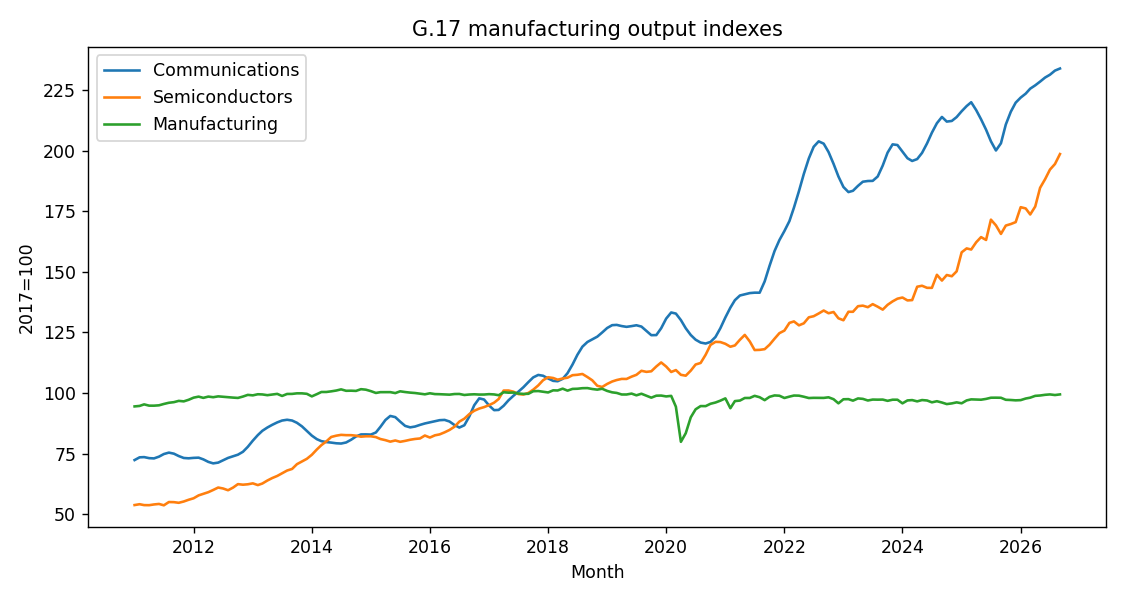

In [7]:
display(Image(filename=str(ROOT/"figures/01_output_levels.png"),width=680))

## 04. Data & Source Integrity

Four frozen monthly series: `IPG3342S` (communications output, target), `IPG3344S` (semiconductor components), `IPG3341S` (computer equipment control) and `IPMAN` (aggregate manufacturing). The raw CSV has 189 complete monthly observations from January 2011 to September 2026, and matches **Git blob SHA `3d111120b93de0a5eb153d794772225f5dd1a6c4`** of the earlier semiconductor research input byte-for-byte. Source register `data/source_register.csv` records original URLs, publishers, grade A official provenance versus grade B inherited copy, release date, observation span, units and revision caveats. Checks verify continuous months, positive values, nonmissing data and expected columns. No source publication date is invented: historical release-vintage timestamps remain UNKNOWN.

In [8]:
src=pd.read_csv(ROOT/"data/source_register.csv");display(src[["source_id","grade","publisher","publication_date","revision_or_vintage"]])

,source_id,grade,publisher,publication_date,revision_or_vintage
0,FED_G17,A,Federal Reserve Board,2026-10-16,October 2026 revised release; individual histo...
1,IPG3342S,A,Federal Reserve via FRED,2026-10-16,Latest revised snapshot; historical vintage UN...
2,IPG3344S,A,Federal Reserve via FRED,2026-10-16,Latest revised snapshot; historical vintage UN...
3,IPG3341S,A,Federal Reserve via FRED,2026-10-16,Latest revised snapshot; historical vintage UN...
4,IPMAN,A,Federal Reserve via FRED,2026-10-16,Latest revised snapshot; historical vintage UN...
5,REPO_SNAPSHOT,B,Signals-to-Alpha repository,2026-10-19,Exact Git blob SHA 3d111120b93de0a5eb153d79477...
6,NAICS,A,U.S. Census Bureau,2022,Classification revision 2022
7,CIEN_10K,A,U.S. SEC,2025-12-12,2025 fiscal filing; no historical exposure panel
8,CSCO_REPORT,A,Cisco Systems,2025,2025 annual report; no historical exposure panel


In [9]:
print("Source snapshot shape:",raw.shape,"| monthly dates:",raw.date.min().date(),raw.date.max().date())
print("Missing cells:",int(raw.isna().sum().sum()),"| all levels positive:",bool((raw.drop(columns="date")>0).all().all()))
print("Exact inherited blob match:",ra.git_blob_sha(ra.RAW.read_bytes())==ra.EXPECTED_GIT_BLOB)

Source snapshot shape: (189, 5) | monthly dates: 2011-01-01 2026-09-01
Missing cells: 0 | all levels positive: True
Exact inherited blob match: True


## 05. Point-in-Time Availability

At month *t* the formation features use observations at **t−2** or earlier, allowing for publication delay; the 3-month-ahead target is `g_comm(t+3)`. Training origin *u* is eligible only when **u+3 ≤ t−2**, so all training labels are mature before formation. The 2026-revised snapshot was **not** available in 2011–2025, however; applying a two-month buffer does not cure vintage leakage. This is a retrospective fixed-snapshot study, explicitly **not PIT**. Future work requires a Federal Reserve/ALFRED release-vintage panel and exact publication timestamps.

In [10]:
panel=ra.build_panel(raw)
print("Formation features are observed t-2; target is g_comm(t+3). First 3 rows:")
display(panel[["date","origin_index","comm_available","sem_available","man_available","factor","target"]].head(3))

Formation features are observed t-2; target is g_comm(t+3). First 3 rows:


,date,origin_index,comm_available,sem_available,man_available,factor,target
0,2012-06-01,17,-2.134596,9.523673,3.872827,0.359858,-1.461678
1,2012-07-01,18,-2.845114,10.494133,3.616955,0.428843,0.759857
2,2012-08-01,19,-3.398094,11.771070,3.816178,0.485630,3.432040


In [11]:
wf=pd.read_csv(ROOT/"results/walk_forward_oos.csv",parse_dates=["date"])
assert (wf.max_train_label_observation<=wf.latest_usable_observation).all()
print("All OOS origins purged:",len(wf),"| min train:",wf.n_train.min(),"| max train:",wf.n_train.max())

All OOS origins purged: 110 | min train: 55 | max train: 164


## 06. Factor Construction

For series *j*, define `g_j(s)=100 ln(IP_j(s)/IP_j(s−12))`, in log percentage points. The predeclared, bounded signal is **`F(t)=tanh((g_sem(t−2)−g_man(t−2))/15)`**; 15 is a fixed scale in log percentage points, not fitted on the full sample. The target is `Y(t)=g_comm(t+3)`. The fixed sensitivity family replaces `g_sem` with `w*g_sem+(1−w)*g_computer` for 1,000 weights `w~Uniform(0.8,1.0)`, with seed 20261030; this is a *perturbation*, not an optimized production factor. All feature transforms are computed without looking ahead.

In [12]:
t=panel.iloc[0];print("First factor row:",t.date.date(),"| F(t):",round(t.factor,6),"| manual:",round(float(np.tanh((t.sem_available-t.man_available)/15)),6))
print("Feature min/max:",panel.factor.min(),panel.factor.max(),"| no train-set fitted weights")

First factor row: 2012-06-01 | F(t): 0.359858 | manual: 0.359858
Feature min/max: -0.41973573684747834 0.9162811164827726 | no train-set fitted weights


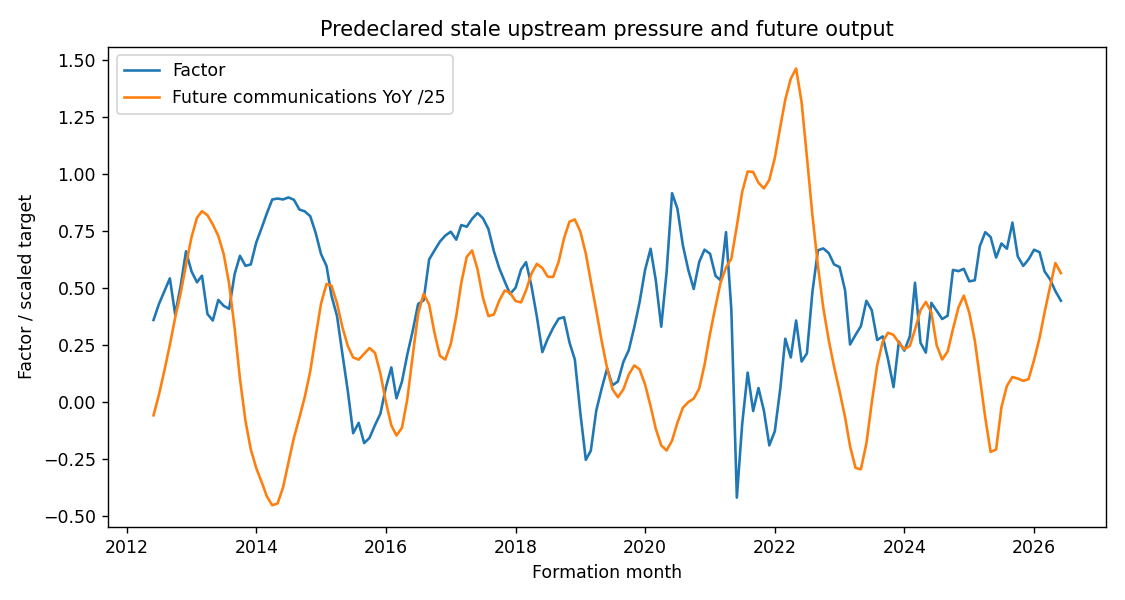

In [13]:
display(Image(filename=str(ROOT/"figures/03_signal_and_target.png"),width=680))

## 07. Exposure & Transmission

`data/company_exposure_map.csv` separates the **NAICS industry-level** 3342 target (weight 1.0), upstream 3344 input (weight 1.0 in the factor) and 3341 control from **descriptive issuer mapping**. Ciena's fiscal 2025 10-K reports Networking Platforms revenue **$3,676,377 thousand**, while Cisco's fiscal 2025 annual report reports Networking product revenue **$28,304 million**. These are *2025 global company categories*, not historical domestic NAICS production weights; issuer model weights are **NA**. Neither issuer is in the statistical target or return backtest. There is **no company panel**, so leave-one-company-out is **not applicable**; leave-one-OOS-year-out is used only as a time robustness diagnostic.

In [14]:
exposure=pd.read_csv(ROOT/"data/company_exposure_map.csv");display(exposure[["entity","as_of","role","model_weight","qualification"]])

,entity,as_of,role,model_weight,qualification
0,NAICS 3342,2022 classification,target sector,1.0,Industry target not an investable portfolio
1,NAICS 3344,2022 classification,upstream supplier proxy,1.0,Factor numerator proxy not issuer revenue
2,NAICS 3341,2022 classification,related equipment control,0.0,Used only as control and sensitivity mixture
3,Ciena (CIEN),2025-11-01,contextual issuer,NaN,Not a 2011-2026 US NAICS exposure; not include...
4,Cisco (CSCO),2025-07-26,contextual issuer,NaN,Not a 2011-2026 US NAICS exposure; not include...


In [15]:
print("Issuer-level time series:","NOT AVAILABLE","| leave-one-company-out:","NOT APPLICABLE")

Issuer-level time series: NOT AVAILABLE | leave-one-company-out: NOT APPLICABLE


## 08. Outcomes & Baselines

The sole modeled outcome is **future U.S. communications-equipment industrial production YoY log growth**. Independent firm revenue, EPS, total-return and benchmark-adjusted return tests are **NOT PERFORMED**. All six forecasts share the same 110 OOS origins: expanding historical mean; stale communications persistence; persistence plus 3-month momentum; macro Ridge with stale communications, momentum, aggregate manufacturing and computer production; macro plus `F(t)`; and factor-only Ridge. Ridge penalty is fixed `alpha=10`; predictors are standardized **within each training window**; no post-selection tuning. First origin is 2017-05, and training labels are purged through `u+3<=t−2`. Evaluation uses RMSE, MAE, paired squared-loss diagnostics and sample counts, not invented stock IC or long-short spreads.

In [16]:
score=pd.read_csv(ROOT/"results/scorecard.csv");display(score.sort_values("rmse_log_pp"))

,model,n,rmse_log_pp,mae_log_pp
4,full,110,8.384024,6.735598
3,macro,110,8.451595,6.802667
2,momentum,110,8.680798,7.053247
1,persistence,110,8.978809,7.296455
5,factor_only,110,9.643509,7.832558
0,mean,110,10.269720,8.205547


In [17]:
print("Target is future NAICS 3342 output YoY log growth, not equity return. Forecast origins:",wf.date.min().date(),"to",wf.date.max().date())
print("Ridge scaling is train-only; no hyperparameter search; all models share the same origin dates.")

Target is future NAICS 3342 output YoY log growth, not equity return. Forecast origins: 2017-05-01 to 2026-06-01
Ridge scaling is train-only; no hyperparameter search; all models share the same origin dates.


## 09. Empirical Findings

On 110 origins, OOS RMSE (log pp) is **mean 10.2697**, **persistence 8.9788**, **momentum 8.6808**, **macro 8.4516**, **macro + factor 8.3840**, and **factor only 9.6435**. The observed macro-minus-full improvement is **+0.0676 log pp** (about **0.8% of the macro RMSE**), with full-model MAE **6.7356** vs macro **6.8027**. The full-panel contemporaneous formation-factor/future-target correlation is **−0.3577**, contradicting a simple monotone positive mechanism and cautioning against interpreting the small OOS gain as a causal supply relationship. See `results/scorecard.csv`, `results/walk_forward_oos.csv`, and ten actual computed figures.

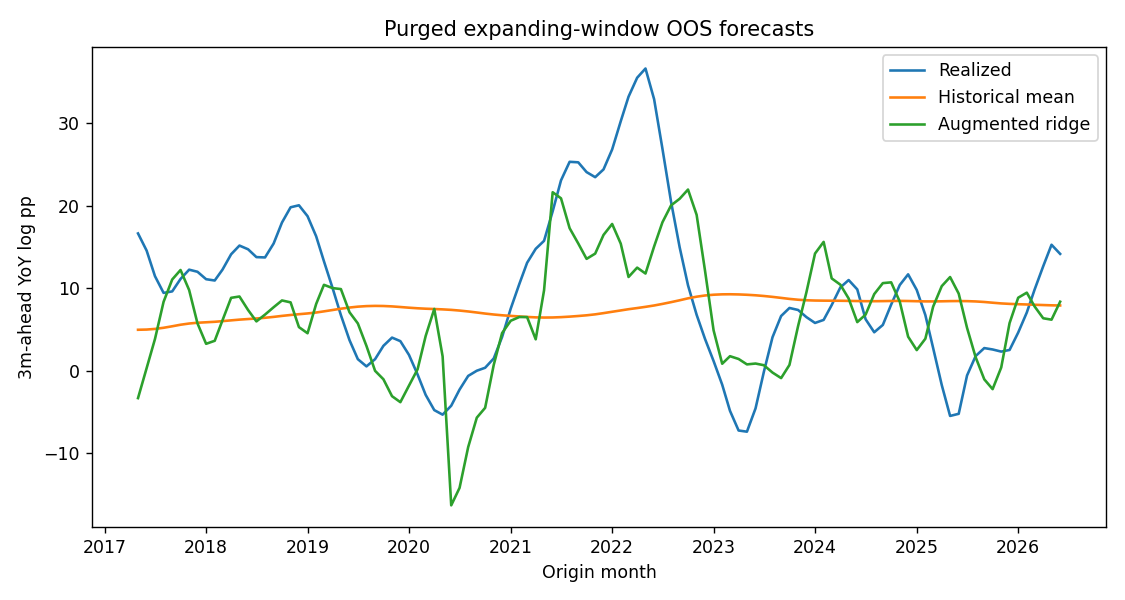

In [18]:
display(Image(filename=str(ROOT/"figures/04_oos_forecasts.png"),width=680))

In [19]:
gain=ra.rmse(wf.target,wf.macro)-ra.rmse(wf.target,wf.full)
print("Control-minus-full RMSE:",gain,"| paired MAE improvement:",ra.mae(wf.target,wf.macro)-ra.mae(wf.target,wf.full))
print("Full-panel factor/target correlation:",panel[["factor","target"]].corr().iloc[0,1])

Control-minus-full RMSE: 0.06757102775771351 | paired MAE improvement: 0.06706954739315485
Full-panel factor/target correlation: -0.35771443852570606


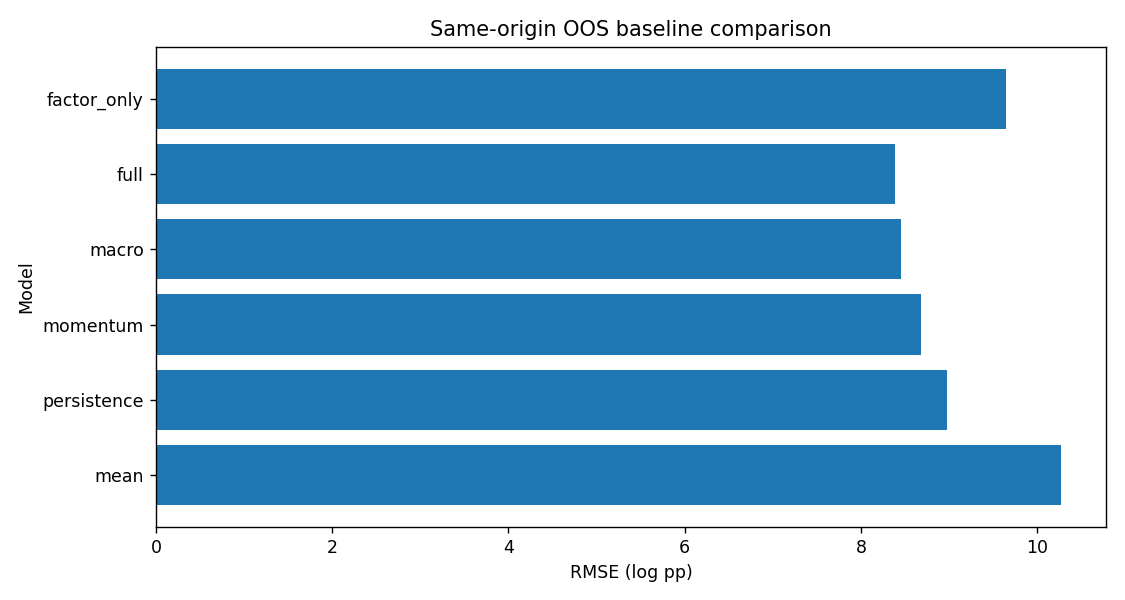

In [20]:
display(Image(filename=str(ROOT/"figures/05_rmse_scorecard.png"),width=680))

## 10. Robustness & Placebos

**Block-aware placebo:** 1,000 random reorderings of contiguous 12-month signal blocks, with the same expanding-window full-model refits; the upper-tail fraction `(1+#{null gain>=observed})/1001` is **0.1678**. This is an *exploratory randomization diagnostic*, not an exact p-value for a dependent time series. **Uncertainty:** 2,000 paired 12-month moving-block bootstrap resamples of the OOS forecast-error vectors give 95% RMSE-improvement interval **[−0.1885, 0.2816] log pp**, including zero. **Exposure:** 1,000 `w∈[0.8,1.0]` mixes yielded positive macro-relative improvements, but they are highly correlated variants of the same source and cannot establish significance. **Ablations:** removing the computer control improves fit, while removing momentum or manufacturing harms fit; the factor is not a stable standalone replacement. **Year exclusions:** every OOS year is excluded in turn and scored on remaining predictions; this is not leave-one-firm-out.

In [21]:
pl=pd.read_csv(ROOT/"results/block_placebo_1000.csv");bs=pd.read_csv(ROOT/"results/block_bootstrap_2000.csv");ex=pd.read_csv(ROOT/"results/exposure_perturbation_1000.csv")
print("Refit block-shuffle N:",len(pl),"| exploratory upper-tail:",(1+(pl.delta_rmse>=gain).sum())/(len(pl)+1))
print("Paired block bootstrap N:",len(bs),"| 95% interval:",bs.delta_rmse.quantile([.025,.975]).to_dict())
print("Exposure perturbation N:",len(ex),"| fraction positive:",(ex.delta_rmse>0).mean())

Refit block-shuffle N: 1000 | exploratory upper-tail: 0.16783216783216784
Paired block bootstrap N: 2000 | 95% interval: {0.025: -0.18845427879249999, 0.975: 0.28156964471999996}
Exposure perturbation N: 1000 | fraction positive: 1.0


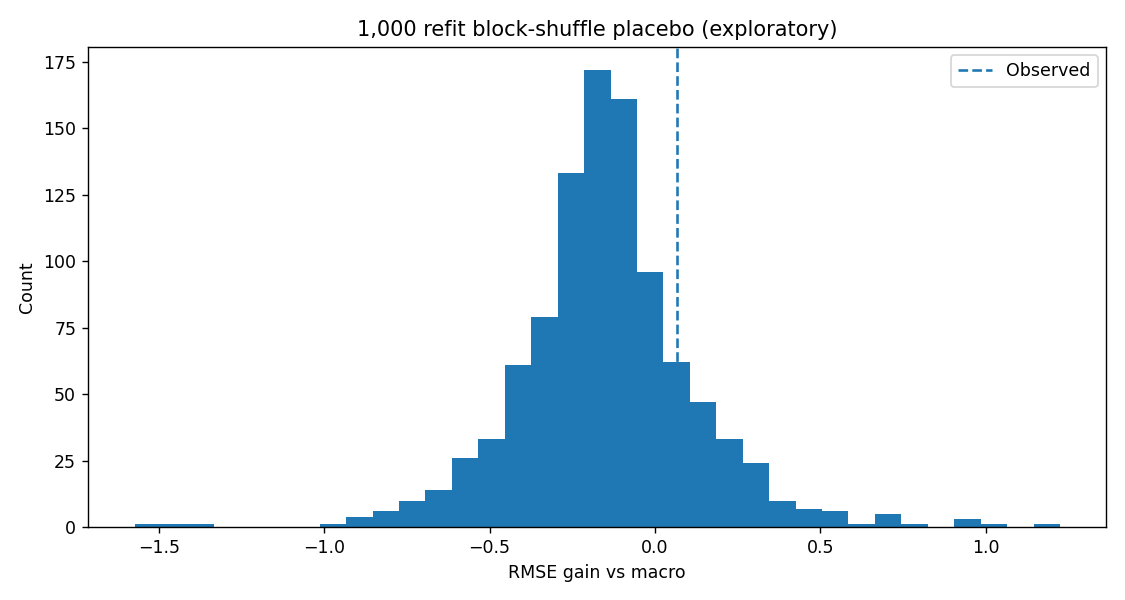

In [22]:
display(Image(filename=str(ROOT/"figures/07_block_placebo.png"),width=680))

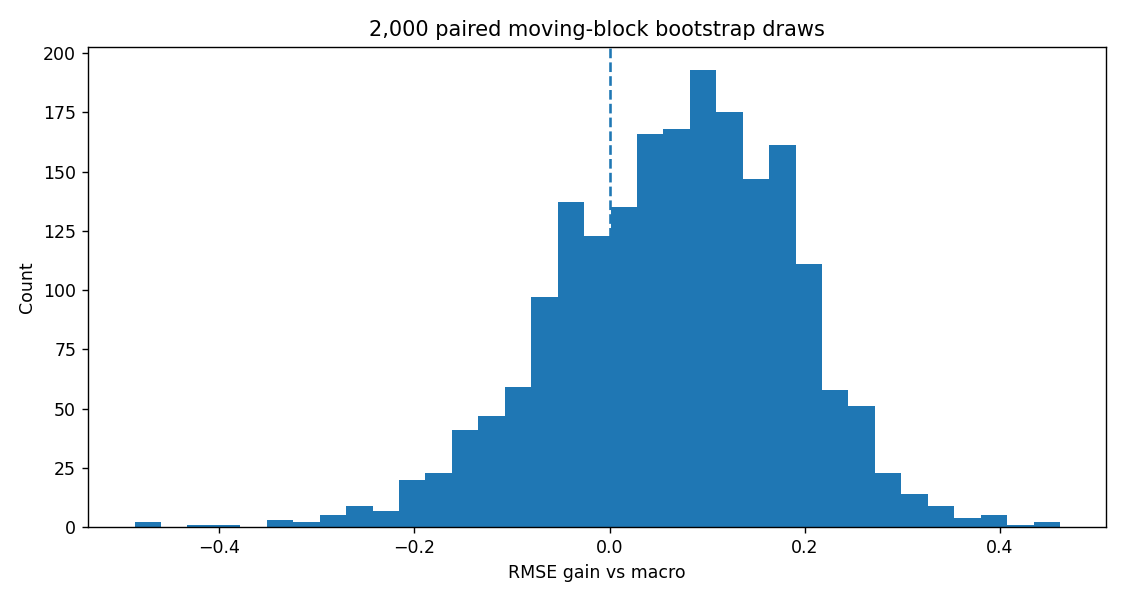

In [23]:
display(Image(filename=str(ROOT/"figures/08_bootstrap.png"),width=680))

In [24]:
abl=pd.read_csv(ROOT/"results/ablations.csv");display(abl)
loyo=pd.read_csv(ROOT/"results/leave_one_year_out.csv");print("LOYO years:",len(loyo),"| positive:",int((loyo.delta_rmse>0).sum()))

,ablation,rmse,delta_vs_macro
0,no_momentum,8.983251,-0.531656
1,no_computer,8.194993,0.256602
2,no_manufacturing,8.789664,-0.338068


LOYO years: 10 | positive: 9


## 11. Regime Sensitivity

Macro-minus-full OOS RMSE improvements are **+0.1405** across 32 pre-2020 origins, **−0.3527** across 24 2020–2021 origins, and **+0.1792** across 54 post-2021 origins. The pre-2020 full model still fails that subsample's historical mean (**7.9670 vs 7.6122**). Horizon/lag tests find the main 3-month horizon benefit turns negative at **6 months** for all tested publication buffers (1–4 months), and at **4-month lag** even the 3-month forecast loses the gain. These are exploratory robustness diagnostics, not newly selected optimal parameters.

In [25]:
reg=pd.read_csv(ROOT/"results/regimes.csv");display(reg)
sensitivity=pd.read_csv(ROOT/"results/horizon_lag.csv");display(sensitivity.pivot(index="lag_months",columns="horizon_months",values="delta_rmse"))

,regime,n,delta_rmse,rmse_mean,rmse_full
0,pre2020,32,0.140451,7.612174,7.967044
1,pandemic2020_2021,24,-0.352722,11.478123,7.442382
2,post2021,54,0.179240,11.043018,8.997537


horizon_months,1,3,6
lag_months,,,
1,0.056221,0.078738,-0.035518
2,0.074076,0.067571,-0.125339
3,0.075776,0.034650,-0.186992
4,0.067307,-0.029631,-0.215779


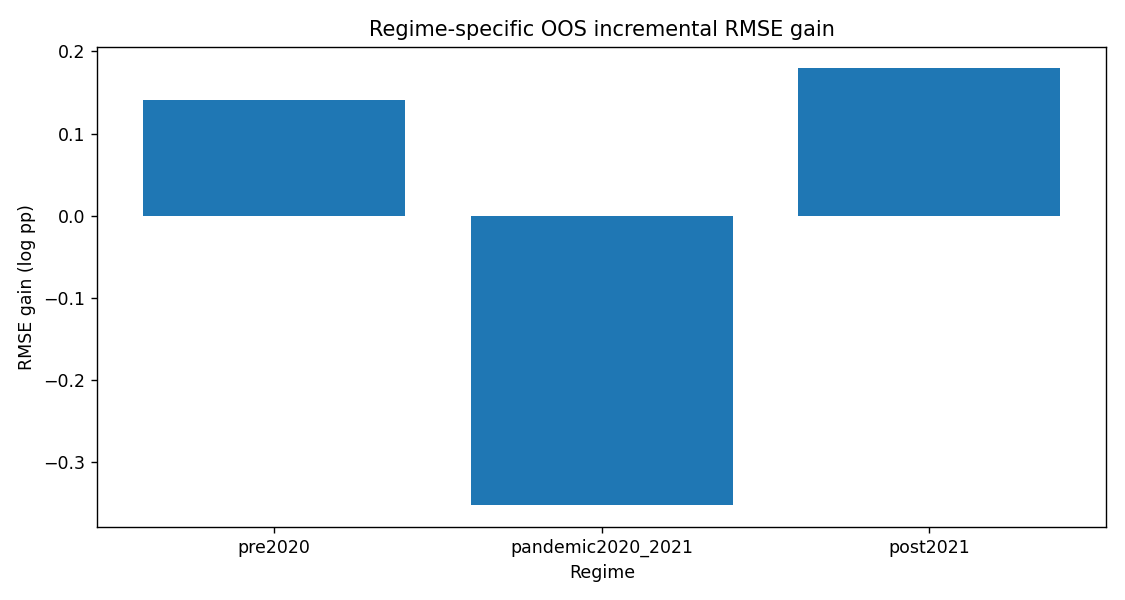

In [26]:
display(Image(filename=str(ROOT/"figures/10_regime_sensitivity.png"),width=680))

## 12. Bias Audit & Verdict

**Vintage/revisions:** 2026 snapshot retroactively applied to past origins; **PIT unverified**. **Selection/multiple testing:** new sector and directional hypothesis follow 23 prior studies; no familywise error adjustment; optimistic risk. **Survivorship/exposure:** aggregate NAICS data hide firm exits and offshore manufacturing; no issuer panel. **Time dependence:** overlapping YoY targets and 3-month horizons reduce effective independent sample size; block bootstrap is approximate. **Execution/costs:** no prices, portfolio, transaction costs, slippage, borrow or capacity. **Economic interpretation:** upstream growth could reflect global demand rather than domestic component availability, and factor–target correlation sign conflicts with the simplest thesis. **Verdict: weak retrospective incremental predictive gain, statistically inconclusive, no validated PIT fundamental lead or investable equity alpha.**

In [27]:
audit={"historic_first_release_vintage":"UNKNOWN","latest_revised_source":True,"issuer_fundamentals":False,"total_return_and_benchmark":False,"transaction_costs":False,"multiple_testing_adjusted":False,"overlapping_labels":True};display(pd.Series(audit,name="audit_status"))

historic_first_release_vintage    UNKNOWN
latest_revised_source                True
issuer_fundamentals                 False
total_return_and_benchmark          False
transaction_costs                   False
multiple_testing_adjusted           False
overlapping_labels                   True
Name: audit_status, dtype: object

In [28]:
print("Conditional verdict:","small macro OOS gain; placebo not compelling; bootstrap includes zero; not PIT; not equity alpha.")

Conditional verdict: small macro OOS gain; placebo not compelling; bootstrap includes zero; not PIT; not equity alpha.


## 13. Reproduction

From this directory in a clean Python environment, install `python -m pip install -r requirements.txt`; run `OPENBLAS_NUM_THREADS=1 python run_analysis.py` to regenerate all results, then `OPENBLAS_NUM_THREADS=1 python -m pytest -q tests`, and `OPENBLAS_NUM_THREADS=1 jupyter nbconvert --to notebook --execute --inplace research.ipynb --ExecutePreprocessor.timeout=900`. Run `python scripts/validate_studies.py` **from the repository root**. The full 1,000/2,000/1,000 resampling draws are stored as CSV, and all notebook code cells have executed outputs. Reproduction should not require network access because the raw snapshot is frozen. GitHub Actions structural validation is distinct from numeric reruns.

In [29]:
print("Reproducing heavy computations with deterministic seed; please wait...")
reproduced=ra.compute_all(n_placebo=1000,n_boot=2000,n_exposure=1000)
print("Computed from frozen raw:",reproduced["n_oos"],"OOS origins; gain:",reproduced["primary_delta_rmse_log_pp"])

Reproducing heavy computations with deterministic seed; please wait...


Computed from frozen raw: 110 OOS origins; gain: 0.0675710280861388


In [30]:
assert np.isclose(reproduced["primary_delta_rmse_log_pp"],gain)
assert reproduced["block_shuffle_draws"]==1000 and reproduced["bootstrap_draws"]==2000 and reproduced["exposure_draws"]==1000
print("Notebook heavy analysis and numerical assertions passed.")

Notebook heavy analysis and numerical assertions passed.


## 14. Next-Stage Protocol

(1) Independently retrieve official machine-readable G.17 data and reconcile every 2011–2026 observation, then reconstruct first-available vintages and precise release times. (2) Obtain historical firm product/segment revenues and filing timestamps for a defensible issuer-by-year NAICS exposure map; test fundamental growth on genuinely independent firm observations. (3) Obtain delisting-inclusive total returns, benchmark and sector controls, point-in-time investable universe, transaction costs and out-of-sample selection-adjusted holdouts. (4) Pre-register one horizon and a finite set of features before looking at post-2026 data; report multiple-testing adjustment across prior hypotheses. No claim of investability is warranted until these steps succeed.

In [31]:
print("Next stage: ALFRED/Federal Reserve first-release vintages; issuer-by-year product revenue + filing dates; delisting-inclusive total returns; preregistered holdout.")

Next stage: ALFRED/Federal Reserve first-release vintages; issuer-by-year product revenue + filing dates; delisting-inclusive total returns; preregistered holdout.


## 15. Sources & Artifacts

Official sources: [Federal Reserve G.17](https://www.federalreserve.gov/releases/g17/) (2026-10-16 release), [IPG3342S](https://fred.stlouisfed.org/series/IPG3342S), [IPG3344S](https://fred.stlouisfed.org/series/IPG3344S), [IPG3341S](https://fred.stlouisfed.org/series/IPG3341S), [IPMAN](https://fred.stlouisfed.org/series/IPMAN), [U.S. Census NAICS](https://www.census.gov/naics/), [Ciena fiscal 2025 10-K](https://www.sec.gov/Archives/edgar/data/936395/000162828025056698/cien-20251101.htm) and [Cisco annual reports](https://www.cisco.com/c/en/us/about/annual-reports.html). Original inherited frozen file: [Semiconductor study G.17 CSV](../Semiconductor-Device-Gap-to-Alpha-U.S.-Chip-Manufacturing/data/fred_g17_snapshot_2011_2026.csv). Machine-readable source register and publication caveats: `data/source_register.csv` and `data/provenance_audit.md`. Raw/derived: `data/`; Python analysis: `run_analysis.py`; executed computational paper: `research.ipynb`; empirical tables: `results/`; ten diagnostics: `figures/`; tests: `tests/`. Research failure and uncertainty are part of the deliverable, not grounds for changing the headline ex post.

In [32]:
print("A/B/C source register and frozen data:");display(src[["source_id","original_url","role"]])

A/B/C source register and frozen data:


,source_id,original_url,role
0,FED_G17,https://www.federalreserve.gov/releases/g17/,release calendar and methodology
1,IPG3342S,https://fred.stlouisfed.org/series/IPG3342S,primary communications production outcome
2,IPG3344S,https://fred.stlouisfed.org/series/IPG3344S,upstream factor
3,IPG3341S,https://fred.stlouisfed.org/series/IPG3341S,control and exposure perturbation
4,IPMAN,https://fred.stlouisfed.org/series/IPMAN,macro control and relative factor denominator
5,REPO_SNAPSHOT,https://github.com/HyeonbinJung/Signals-to-Alp...,byte-verified frozen research input
6,NAICS,https://www.census.gov/naics/,industry definition and mapping
7,CIEN_10K,https://www.sec.gov/Archives/edgar/data/936395...,descriptive issuer mapping only
8,CSCO_REPORT,https://www.cisco.com/c/en/us/about/annual-rep...,descriptive issuer mapping only


In [33]:
print("Reproduction artifacts:",len(list((ROOT/"figures").glob("*.png"))),"figures,",len(list((ROOT/"results").glob("*.csv"))),"result CSVs")
print("Final verdict:","REPRODUCED RETROSPECTIVE MACRO PILOT — NOT PIT / NOT INVESTABLE ALPHA")

Reproduction artifacts: 10 figures, 9 result CSVs
Final verdict: REPRODUCED RETROSPECTIVE MACRO PILOT — NOT PIT / NOT INVESTABLE ALPHA


### Publication integrity check

The exact source Git blob and all calculations are reproducible, but the original G.17 historical release vintages, independent issuer fundamentals and investable returns are **not**. An apparent gain must not be promoted to a validated trading strategy. The next research run should use a genuinely independent dataset and a preregistered test.